In [1]:
import os
import platform
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt

import belfast.mcmc_utils as mcmc
from belfast.target_utils import query_data
from belfast.target_definition import Target


# Prepare data


## Querying data from 2MASS, Tycho-2, and Gaia DR3

In [2]:
cluster         = 'Pleiades'
target_name     = 'HIP 17034'

# set extinction
extinction_type ='A_V' #' A_V' or 'EB_V', or 'EBP_RP'
extinction      = 0.105
extinction_err  = 0.01

In [3]:
target_name = target_name.strip()
obs_mags, obs_err_mags, vsini_obs, vsini_obs_err, parallax_obs, parallax_obs_err,\
    EBP_RP_obs, EBP_RP_obs_lower, EBP_RP_obs_upper, additional_info = query_data(target_name,  return_df=False)

Target : HIP 17034
IDs    : Gaia DR3 68540535515653504 | HIP 17034 | HD 22614 | 2MASS J03390671+2442102
-----------------------------------------------------------------------------------------------------------------------------
General info                       | Gaia DR3                                      | Tycho-2                                 
RA            : nan                | G        :   7.1034 ±   0.0005 mag            | B_T :   7.1480 ±   0.0150 mag           
Dec           : nan                | G_BP     :   7.1052 ±   0.0011 mag            | V_T :   7.1040 ±   0.0100 mag           
Spectral Type : nan                | G_RP     :   7.0665 ±   0.0007 mag            | ----------------------------------------
Object Type   : nan                | Parallax :   7.7028 ±   0.0338 mas            | 2MASS                                   
Distance      : 129.82 ± 0.57 pc   | RUWE     :   1.0060                           | J   :   6.9790 ±   0.0240 mag           
              

# Set Target

In [4]:
target = Target(
    name = target_name,
    bands_list = ['G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks'],
    obs_mags = obs_mags,
    obs_err_mags = obs_err_mags,
    vsini_obs = vsini_obs,
    vsini_obs_err = vsini_obs_err,
    parallax_obs = parallax_obs,
    parallax_obs_err = parallax_obs_err,
    sigma_adjustment_parameter = 1,
    extinction_parameter = True,
)

In [5]:
# sample all parameters
target.add_info(
    cluster=cluster,
    sampling_variables_list = ['Mini', 'Age', 'MH', 'omega_ini', 'Inclination', 'parallax'],
    extinction=extinction,
    extinction_err=extinction_err,
    extinction_type=extinction_type,
)

In [ ]:
# # if you want to sample with fixed metallicity [M/H] = 0.0, please give the value by target.known_parameter()
# target.add_info(
#     cluster=cluster,
#     sampling_variables_list = ['Mini', 'logAge', 'omega_ini', 'Inclination', 'parallax'], # not sampling MH
#     extinction=extinction,
#     extinction_err=extinction_err,
#     extinction_type=extinction_type,
# )
#
# target.known_parameter(known_MH=0) # giving fixed MH here


In [ ]:
# # If assuming non-rotation
# target.add_info(
#     cluster=cluster,
#     sampling_variables_list = ['Mini', 'logAge', 'MH', 'parallax'], # not sampling omega_ini and inclination
#     extinction=extinction,
#     extinction_err=extinction_err,
#     extinction_type=extinction_type,
# )
#
# target.known_parameter(known_omega_ini=1e-8, known_Inclination=1e-8)  # giving fixed omega_ini and Inclination here

# Setting method

In [6]:
# Standard Regularization + METHOD DIRECT

target.set_method(
    regrid_type='Mini',
    label_list=[0, 1],
    METHOD='DIRECT',
)

****************************************************************************************************
Using PARSEC isochrones with Mini grids and DIRECT method.
****************************************************************************************************
Age_grid: [1.0, 2001.01341407] Myr
Age_grid shape: (219,)
Loaded regularized Mini grid using ndimage.map_coordinates.
grid_type: with_inc
label_list: [0, 1]
interp_variable_list: ['Mini', 'Age', 'MH', 'omega_ini', 'Inclination']
interp_output_list: ['Mass', 'omega', 'logL', 'logTe', 'Req', 'Rpol', 'G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks']
grid_outputs shape: (1392, 219, 13, 7, 11, 14)
grid_bounds shape: (219, 13, 7, 11, 2)
grid_outputs dtype: float32
grid_bounds dtype: float32
save_float32: True
read_all_at_once: True
total grid memory: 16298.61 MB (15.92 GB)
Axis spacing:
  Mini           : uniform
  Age            : non-uniform
  MH             : non-uniform
  omega_ini      : non-uniform
  Inclination    : non-uniform

In [ ]:
# # Standard Regularization + METHOD PARS
#
# target.set_method(
#     regrid_type='Mini',
#     label_list=[0, 1],
#     METHOD='PARS',
# )

In [ ]:
# # # Reparameterized Regularization + METHOD DIRECT
#
# target.set_method(
#     regrid_type='u',
#     label_list=[0, 1],
#     METHOD='DIRECT',
# )

In [ ]:
# Reparameterized Regularization + METHOD PARS
#
# target.set_method(
#     regrid_type='u',
#     label_list=[0, 1],
#     METHOD='PARS',
# )

In [ ]:
# # MIST isochrones + METHOD PARS
#
# target.set_method(
#     regrid_type='Mini',
#     iso_name='MIST',
#     METHOD='PARS',
# )

# Sampling

In [7]:
# Set initial states and prior distributions for sampling.

target.set_sampling(
    n_walkers=30,
    MH_prior= lambda x: norm.logpdf(x, loc=0.01, scale=0.09),
    extinction_prior = lambda x: norm.logpdf(x, loc=extinction, scale=extinction_err),
)

Sampling parameter space:
Parameter           Min        Max
----------------------------------
Mini             0.0900    14.0000
Age              1.0000  2001.0134
MH              -2.1917     0.3363
omega_ini        0.0000     0.9900
Inclination      0.0000     1.5708
parallax         2.7028    12.7028
extinction       0.0000     1.0000
sigma            0.0000     0.1000


Estimating rough mass...


100%|██████████| 3000/3000 [00:16<00:00, 183.81it/s]


Rough mass is 2.15 M_sun.
====> Using default Vrot prior: 1.90-2.30 Msun
Running a test with 3000 samples...


100%|██████████| 3000/3000 [00:17<00:00, 173.35it/s]


acceptance ratio:
	0.22 0.24 0.21 0.21 0.23 0.22 0.19 0.21 0.18 
	0.19 0.16 0.22 0.21 0.21 0.22 0.22 0.21 0.21 
	0.23 0.22 0.23 0.20 0.22 0.20 0.21 0.23 0.23 
	0.22 0.21 0.22 
mean acceptance ratio: 0.213
n_steps/60: 50.00
autocorrelation time: [112 118 132 148 154 104 137 125]


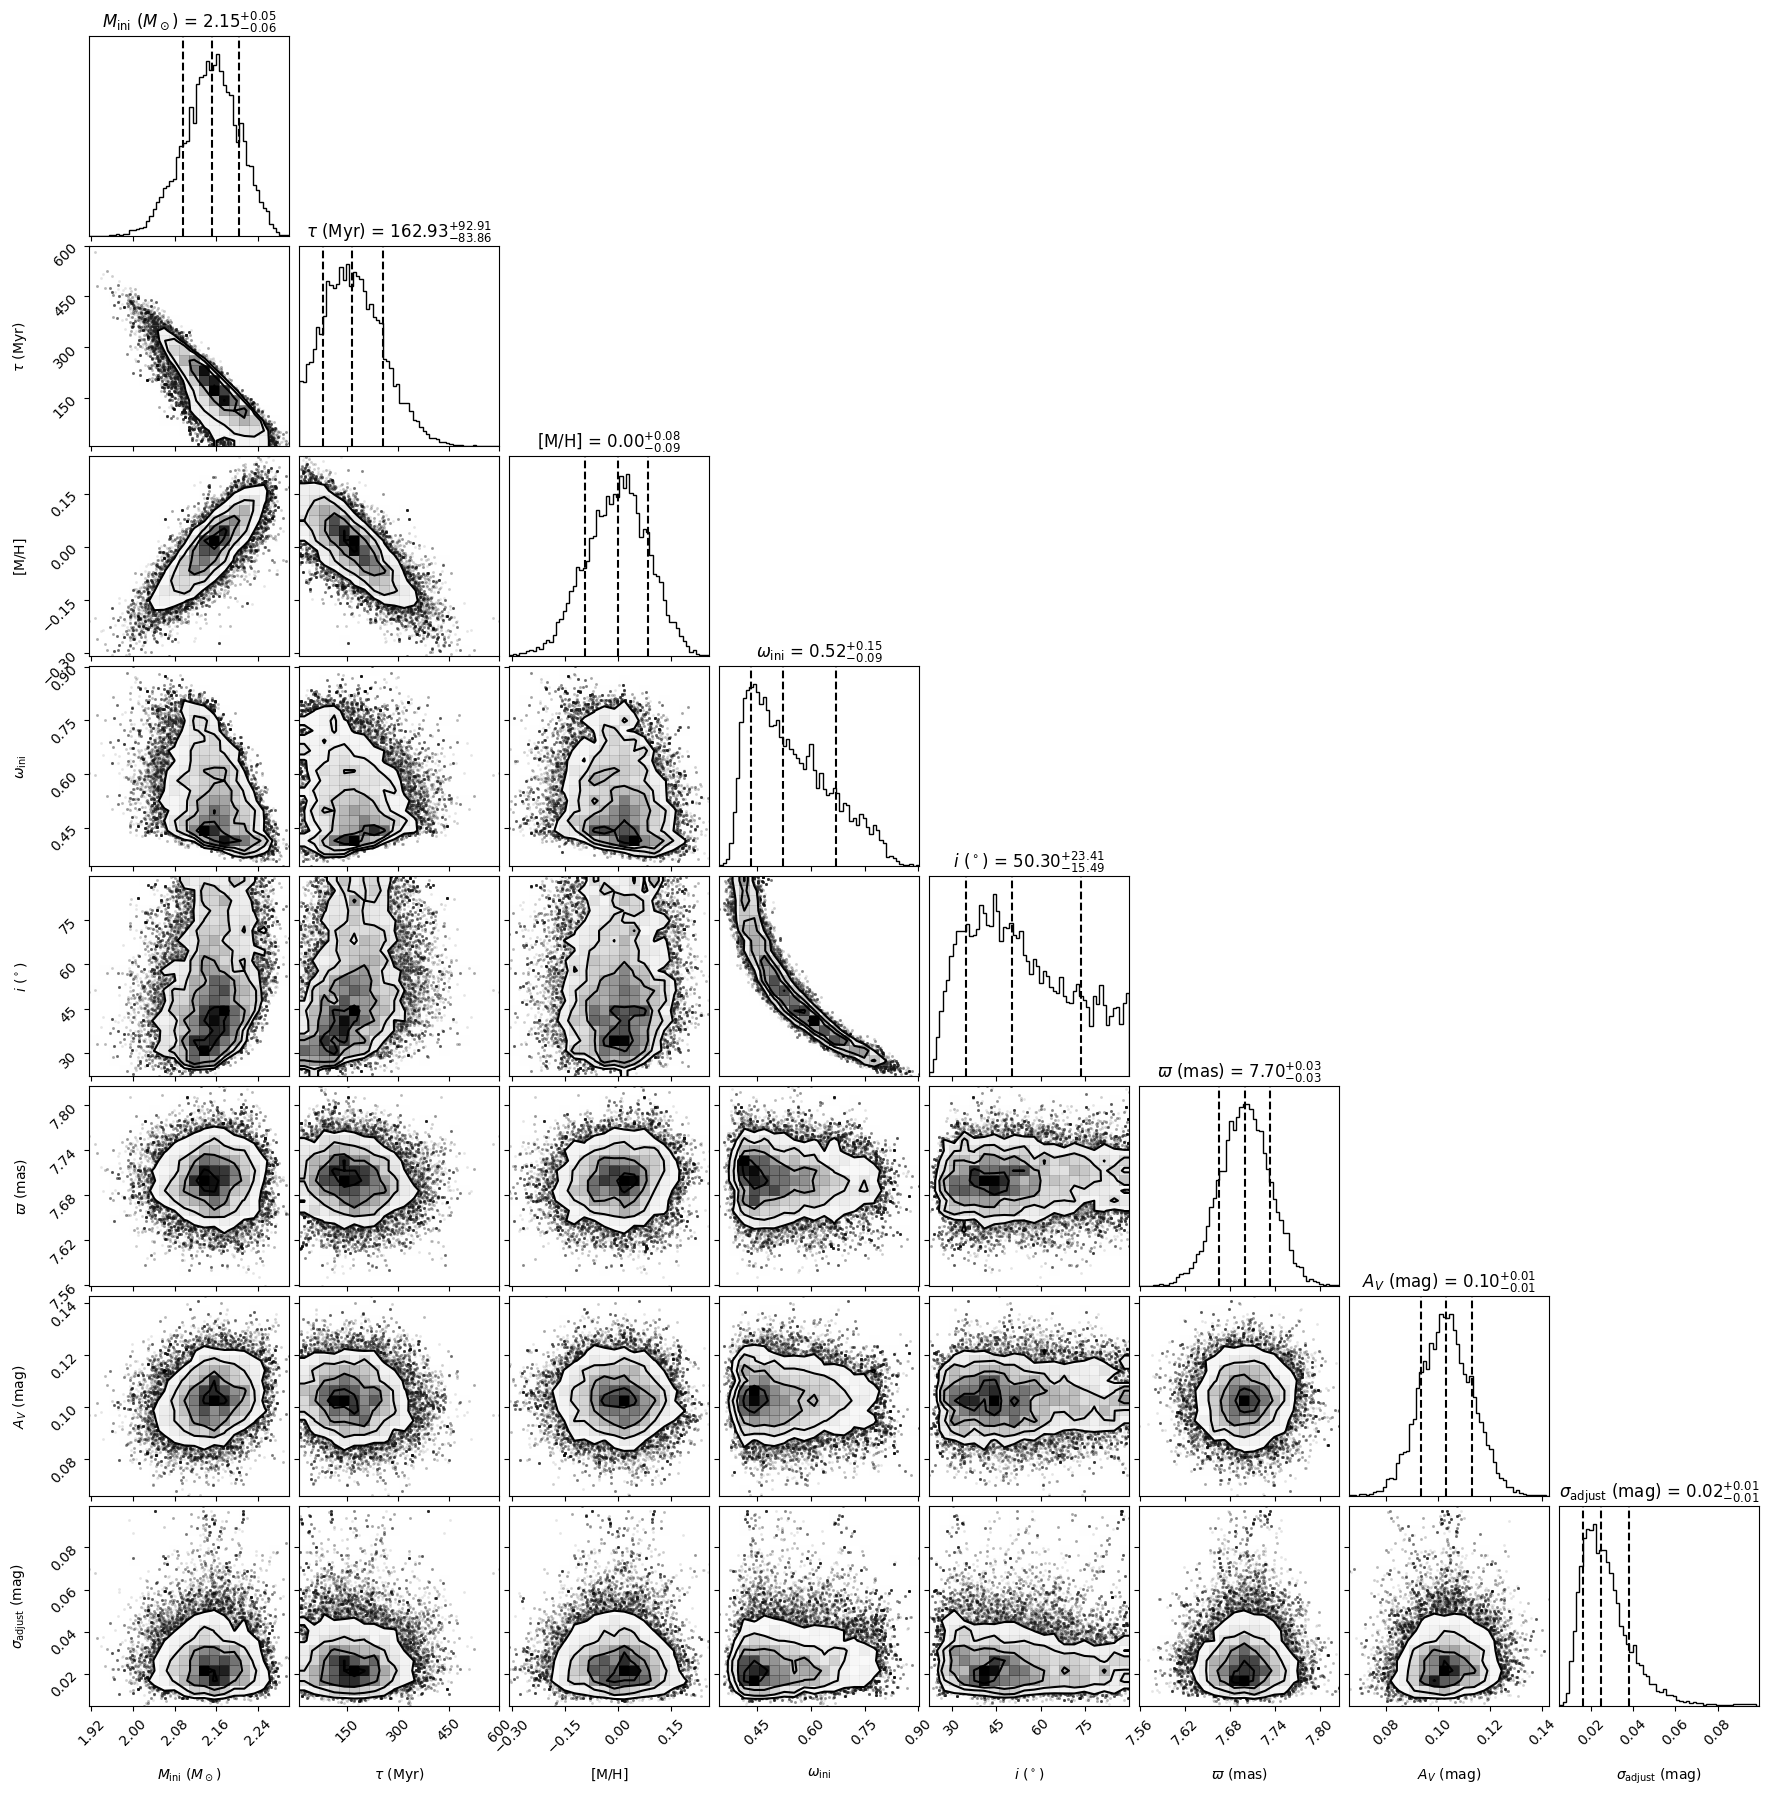

In [9]:
# quick-look tests

mcmc.target = target
sampler_test, target = mcmc.run_test_sampling(
    n_steps_test=3000,
    n_processes=2,
    save_samples=False,
)

In [10]:
# Run sampling!
# Set max time for running and processes for parallel

mcmc.target = target
sampler = mcmc.run_sampling(
    initial_steps = 10000, # the interval for checking convergence (e.g. 10000, 30000, 60000)
    max_hours     = 3, # hours; if reaching max_hours, stop sampling anyway.
    n_processes   = 8, # the number of threads used for parallel sampling.
)

# Play sounds to indicate completion (macOS only).
if platform.system() == "Darwin":
    for _ in range(3):
        os.system("afplay /System/Library/Sounds/Glass.aiff")

🔄 Initial sampling: 10000 steps


100%|██████████| 10000/10000 [00:51<00:00, 195.46it/s]


🚀 Standard criteria: usable N/τ ≥ 70, τ_diff < 20%

🔍 Checkpoint @ 10000 steps (elapsed 0h 0m)
  τ₀․₅=210.1, τ₀․₃=178.1, τ_diff=15.2%
  Usable N/τ after burn=10τ: 37.6 / 70
⏱ Next: 6812 steps (missing 32.4τ, planned 32.4τ)


100%|██████████| 6812/6812 [00:33<00:00, 203.97it/s]



🔍 Checkpoint @ 16812 steps (elapsed 0h 1m)
  τ₀․₅=263.8, τ₀․₃=208.9, τ_diff=20.8%
  Usable N/τ after burn=10τ: 53.7 / 70
⏱ Next: 4291 steps (missing 16.3τ, planned 16.3τ)


100%|██████████| 4291/4291 [00:21<00:00, 202.94it/s]


... (7 outputs left out)

100%|██████████| 3253/3253 [00:16<00:00, 203.30it/s]



🔍 Checkpoint @ 33301 steps (elapsed 0h 2m)
  τ₀․₅=380.0, τ₀․₃=323.3, τ_diff=14.9%
  Usable N/τ after burn=10τ: 77.6 / 70
⏱ Next: 3800 steps (missing 0.0τ, planned 10.0τ)


100%|██████████| 3800/3800 [00:18<00:00, 203.39it/s]



🔍 Checkpoint @ 37101 steps (elapsed 0h 3m)
  τ₀․₅=368.3, τ₀․₃=342.8, τ_diff=6.9%
  Usable N/τ after burn=10τ: 90.7 / 70
✅ Converged: τ stable for 2 checkpoints and usable N/τ ≥ 70
Total sampling time: 00:03:07
Total MCMC steps of each walker: 37101


📏 τ₀․₅=368.3, τ₀․₃=342.8, τ_late=368.3 → burn-in=3682
Results and plots will be saved at
	/Users/ziyinggu/Programming/GitHub/BELFAST/results/HIP_17034_Pleiades_PARSEC_DIRECT_Mini_grid_A_V_sigma1_G-Tomo_A_V_prior;_MH_prior_0.01±0.09
True values: [None, None, None, None, None, None]
Finished saving plots.


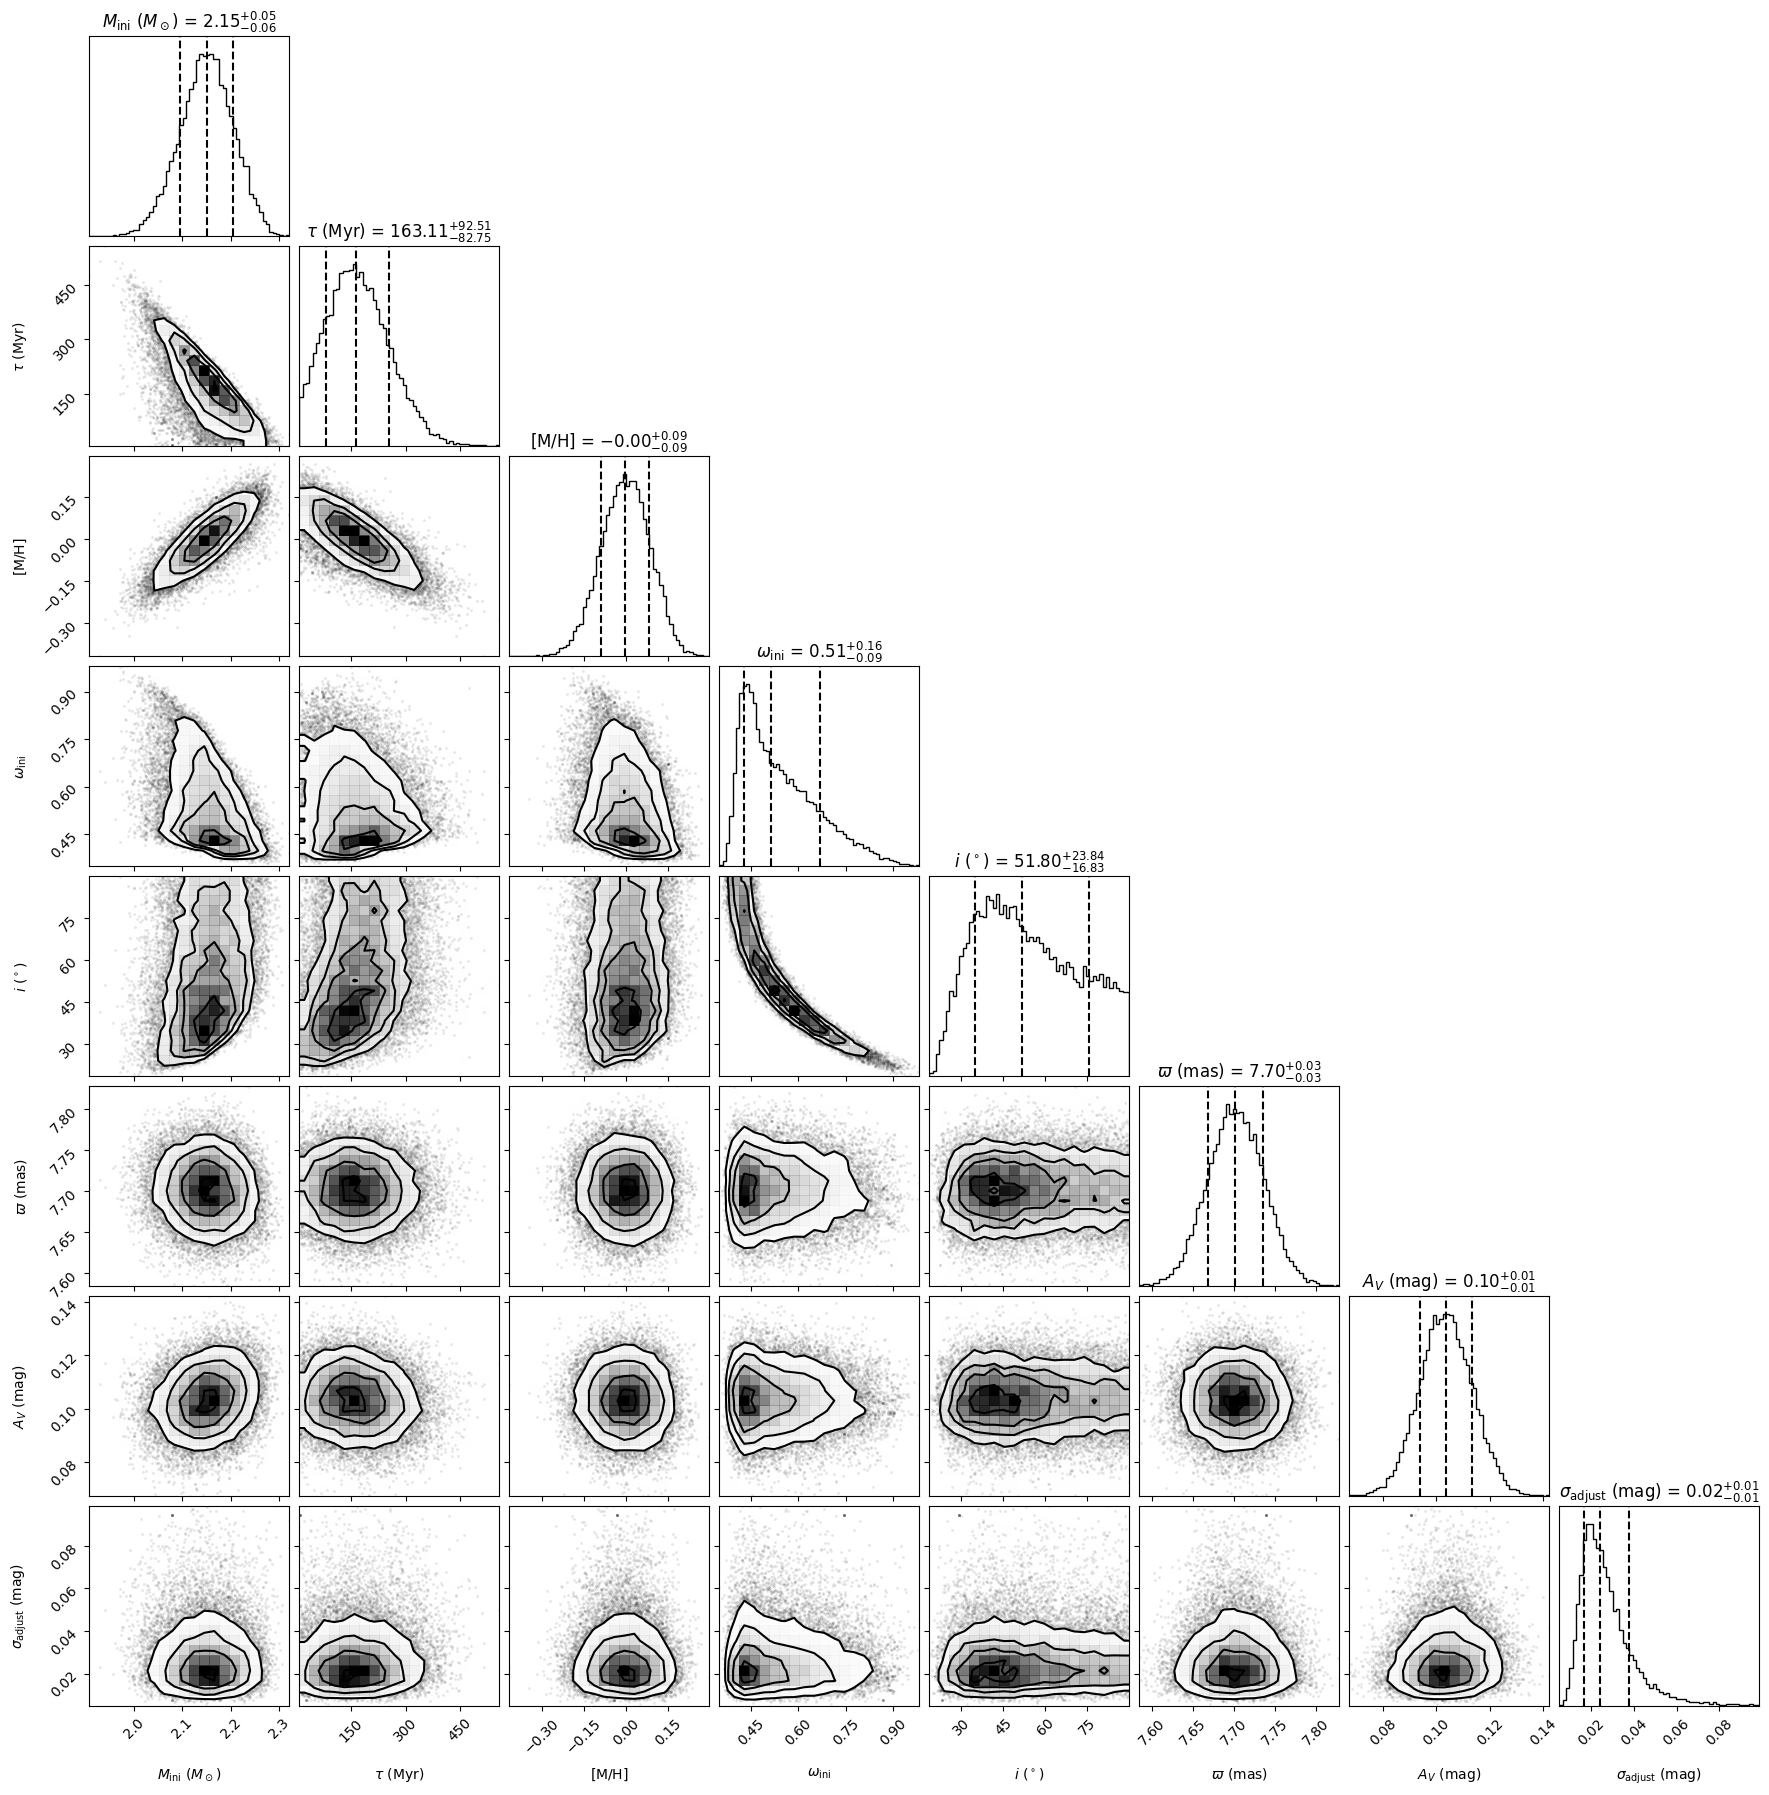

In [11]:
 # Save figures and samples, including corner plot, trace plots for all walkers, target file, and summary of results.

mcmc.target = target
mcmc.save_and_plot(sampler, plot_samples=20000, folder_suffix=f'G-Tomo A_V prior; MH prior 0.01±0.09')

In [12]:
target.check_risk()


## Posterior

Samples           (37101, 30, 6) | Blobs             (37101, 30, 21)
After discard     1,002,570 | Batch size           5,000

## Boundary grid

MH                -0.58314 -- 0.33637 | omega             0.300 -- 0.990
MH grid                N=8 | omega grid             N=6
Posterior Mini    1.890 -- 2.357 | Boundary Mini     1.590 -- 2.657
Mass grid            N=108 | Low-M extrap.         N=22


Classifying samples: 100%|██████████| 1002570/1002570 [00:27<00:00, 36006.51samples/s]


## Classification

Valid             1,002,570 | Invalid                  0
Safe              1,002,570 | Risky                    0
P(safe)            1.00000 | P(risky)           0.00000
